# Shared Criteria Across Questions - ADHD medications and Event terms

**Every research question starts from the same two decisions:**

1. **Which reports are about an ADHD medication?**
2. **Which reported reaction terms count as a event related to cardiovascular, psychiatric, dependence, etc?**


## The Intent of this document is to Describe the process to answer the questions above.

In [ ]:
# @title Getting the data from Motherduck (storage location)

import io
import duckdb
import matplotlib.pyplot as plt
import pandas as pd

#Add Motherduck Token
MOTHERDUCK_TOKEN = #Enter Token with " "

COLORS = {"STIMULANT": "#2a78d6", "NONSTIMULANT": "#eb6834", "MULTI_ADHD_CLASS": "#8a8984"}
GREY, GRID = "#52514e", "#e4e3df"
RAW = {"historical": "faers_2012q4_2021q4", "current": "faers_2022q1_2026q2"}
STUDY = {"historical": "faers_study_2012q4_2021q4", "current": "faers_study_2022q1_2026q2"}
COMBINED = "faers_study_combined"
EVENT_GROUPS = (
    "cardiovascular",
    "psychiatric",
    "dependence",
    "abuse",
    "misuse",
    "addiction",
    "withdrawal",
    "overdose",
    "ineffectiveness",
    "product_quality_supply",
)
SERIOUS = {"death": "DE", "life_threatening": "LT", "hospitalization": "HO"}


def open_databases():
    """Connect to the FAERS databases on MotherDuck (raw, era study and combined)."""
    return duckdb.connect("md:", config={"motherduck_token": MOTHERDUCK_TOKEN})


def _ids(era):
    """Study-group cases counted in ``era``: Meaning the era holding the latest version)."""
    return (
        f"SELECT e.caseid FROM {STUDY[era]}.rq1_exposure e "
        f"JOIN {COMBINED}.combined_cases c ON c.caseid = e.caseid AND c.era = '{era}' "
        "WHERE e.rq1_group IS NOT NULL"
    )


def ingestion_drawdown(con, eras=("historical", "current")):
    """Cases at each preparation step from the FDA files to the ADHD study group."""
    one = lambda sql: con.execute(sql).fetchone()[0]  # noqa: E731
    total = lambda sql: sum(one(sql.format(raw=RAW[e], study=STUDY[e], era=e)) for e in eras)  # noqa: E731
    exposure = (
        "SELECT {what} FROM {study}.rq1_exposure e JOIN "
        + COMBINED
        + ".combined_cases c ON c.caseid = e.caseid AND c.era = '{era}'"
    )
    return pd.Series(
        {
            "Report case versions loaded from the FDA files": total(
                "SELECT count(*) FROM {raw}.raw.demo"
            ),
            "Distinct cases (latest version of each kept)": total(
                "SELECT count(DISTINCT caseid) FROM {raw}.raw.demo"
            ),
            "Removal of FDA deleted cases": total(
                "SELECT count(*) FROM {study}.kept_cases"
            ),
            "Deduplication between our two FAERS databases (combined database)": total(
                f"SELECT count(*) FROM {COMBINED}.combined_cases WHERE era = '{{era}}'"
            ),
            "Cases containing ADHD drug": total(
                exposure.replace("{what}", "count(*)")
            ),
            "...naming an ADHD medicine as primary or secondary suspect": total(
                exposure.replace("{what}", "count(*) FILTER (WHERE e.suspect_adhd)")
            ),
            "Cases identifying an ADHD drug for ADHD use (ADHD Study Group)": total(
                exposure.replace("{what}", "count(*) FILTER (WHERE e.rq1_group IS NOT NULL)")
            ),
        }
    )


def show_drawdown(steps, title):
    """Data Preparation From FDA Files to ADHD Study Group"""
    table = steps.to_frame("cases")
    table["dropped"] = (-steps.diff()).fillna(0).astype(int)
    table["% of previous step"] = (100 * steps / steps.shift()).round(1)
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(steps) + 1))
    ax.barh(range(len(steps)), steps.values, color=GREY)
    for y, v in enumerate(steps.values):
        ax.text(v, y, f" {v:,.0f}", va="center", fontsize=8)
    ax.set_yticks(range(len(steps)), steps.index, fontsize=8)
    ax.invert_yaxis()
    ax.set_xscale("log")
    ax.set_xlabel("cases (log scale)")
    ax.set_title(title)
    plt.show()
    return table


_IDS = {}


def study_ids(con, era):
    """Case ids of the study group counted in ``era``, read once and kept for the session."""
    if era not in _IDS:
        _IDS[era] = [r[0] for r in con.execute(_ids(era)).fetchall()]
    return _IDS[era]


def _fetch(con, era, view, columns):
    """``columns`` of an era view for the study cases, one small query per view."""
    sql = (
        f"SELECT '{era}' AS era, caseid, {columns} FROM {STUDY[era]}.{view} "
        "WHERE caseid IN (SELECT unnest($ids::VARCHAR[]))"
    )
    return con.execute(sql, {"ids": study_ids(con, era)}).df()


def study_rows(con, view, columns, eras=("historical", "current")):
    """Rows of an era study view (``kept_reac``, ``kept_drug_indication``...) for study cases."""
    return pd.concat([_fetch(con, era, view, columns) for era in eras], ignore_index=True)


def study_cases(con, eras=("historical", "current")):
    """One row per ADHD study-group case, built from the post-ingestion study views.

    Each view is read on its own for the study cases; the joins and the event and
    outcome flags are then worked out here, so the database only filters rows.
    """
    groups = event_term_groups()
    read = lambda view, columns: study_rows(con, view, columns, eras)  # noqa: E731
    cases = read(
        "rq1_exposure",
        "rq1_group, rq1_group_confirmed, coalesce(alpha2, false) AS alpha2, "
        "coalesce(concomitant_adhd, false) AS concomitant_adhd",
    )
    demo = read(
        "kept_demo",
        "try_strptime(init_fda_dt, '%Y%m%d')::DATE AS init_date, occp_cod, rept_cod, occr_country",
    )
    people = read(
        "kept_demographics",
        "age_years, coalesce(age_band_fine, 'UNKNOWN') AS age_band, "
        "CASE WHEN sex_category IN ('F', 'M', 'UNKNOWN') THEN sex_category "
        "ELSE 'NOT_REPORTED' END AS sex, wt_kg",
    )
    reac = read("kept_reac", "lower(trim(pt)) AS pt")
    outc = read("kept_outc", "trim(outc_cod) AS outc_cod")
    for g in EVENT_GROUPS:
        for t in ("narrow", "broad"):
            reac[f"{g}_{t}"] = reac["pt"].isin(set(groups[g][t]))
    for name, code in SERIOUS.items():
        outc[name] = outc["outc_cod"] == code
    key = ["era", "caseid"]
    flags = reac.drop(columns="pt").groupby(key).any()
    serious = outc.drop(columns="outc_cod").groupby(key).any().assign(any_outcome_code=True)
    cases = (
        cases.merge(demo.drop_duplicates(key), on=key, how="left")
        .merge(people.drop_duplicates(key), on=key, how="left")
        .merge(flags, on=key, how="left")
        .merge(serious, on=key, how="left")
    )
    filled = [*flags.columns, *serious.columns]
    cases[filled] = cases[filled].fillna(False).astype(bool)
    cases["init_date"] = pd.to_datetime(cases["init_date"])
    return cases


def style():
    plt.rcParams.update(
        {
            "figure.dpi": 90,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "axes.grid": True,
            "grid.color": GRID,
            "axes.titleweight": "bold",
            "axes.titlesize": 11,
        }
    )


style()
con = open_databases()

In [ ]:
# @title Rule Tables
TERMS_CSV = """\
list_version,group,subgroup,tier,pt,note,status
v0.1,cardiovascular,blood_pressure_increased,narrow,hypertension,,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,narrow,blood pressure increased,,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,narrow,blood pressure systolic increased,,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,narrow,blood pressure diastolic increased,,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,narrow,hypertensive crisis,,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,narrow,hypertensive emergency,,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,narrow,hypertensive urgency,,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,narrow,malignant hypertension,,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,narrow,accelerated hypertension,,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,narrow,systolic hypertension,,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,narrow,labile hypertension,,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,narrow,hypertensive encephalopathy,,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,broad,blood pressure fluctuation,nonspecific direction or possibly pre-existing condition,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,broad,blood pressure abnormal,nonspecific direction or possibly pre-existing condition,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,broad,blood pressure systolic abnormal,nonspecific direction or possibly pre-existing condition,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,broad,blood pressure diastolic abnormal,nonspecific direction or possibly pre-existing condition,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,broad,labile blood pressure,nonspecific direction or possibly pre-existing condition,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,broad,blood pressure inadequately controlled,nonspecific direction or possibly pre-existing condition,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,broad,orthostatic hypertension,nonspecific direction or possibly pre-existing condition,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,broad,essential hypertension,nonspecific direction or possibly pre-existing condition,OWNER_APPROVED
v0.1,cardiovascular,blood_pressure_increased,broad,hypertensive heart disease,nonspecific direction or possibly pre-existing condition,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,tachycardia,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,sinus tachycardia,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,heart rate increased,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,palpitations,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,atrial fibrillation,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,atrial flutter,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,atrial tachycardia,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,supraventricular tachycardia,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,tachycardia paroxysmal,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,arrhythmia supraventricular,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,ventricular tachycardia,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,ventricular fibrillation,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,ventricular arrhythmia,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,ventricular tachyarrhythmia,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,tachyarrhythmia,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,arrhythmic storm,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,arrhythmia,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,heart rate irregular,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,extrasystoles,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,ventricular extrasystoles,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,supraventricular extrasystoles,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,torsade de pointes,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,electrocardiogram qt prolonged,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,narrow,long qt syndrome,,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,broad,cardiac flutter,nonspecific rhythm or ECG term,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,broad,cardiac fibrillation,nonspecific rhythm or ECG term,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,broad,heart rate abnormal,nonspecific rhythm or ECG term,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,broad,sinus arrhythmia,nonspecific rhythm or ECG term,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,broad,postural orthostatic tachycardia syndrome,nonspecific rhythm or ECG term,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,broad,electrocardiogram abnormal,nonspecific rhythm or ECG term,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,broad,electrocardiogram qt interval abnormal,nonspecific rhythm or ECG term,OWNER_APPROVED
v0.1,cardiovascular,tachyarrhythmia,broad,electrocardiogram qrs complex prolonged,nonspecific rhythm or ECG term,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,narrow,bradycardia,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,narrow,sinus bradycardia,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,narrow,heart rate decreased,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,narrow,bradyarrhythmia,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,narrow,atrioventricular block,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,narrow,atrioventricular block first degree,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,narrow,atrioventricular block second degree,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,narrow,atrioventricular block complete,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,narrow,sinoatrial block,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,broad,bundle branch block,,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,broad,bundle branch block right,,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,broad,bundle branch block left,,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,broad,conduction disorder,,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,broad,nodal arrhythmia,,OWNER_APPROVED
v0.1,cardiovascular,bradyarrhythmia_conduction,broad,electrocardiogram pr prolongation,,OWNER_APPROVED
v0.1,cardiovascular,hypotension_syncope,narrow,hypotension,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,hypotension_syncope,narrow,blood pressure decreased,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,hypotension_syncope,narrow,blood pressure systolic decreased,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,hypotension_syncope,narrow,blood pressure diastolic decreased,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,hypotension_syncope,narrow,orthostatic hypotension,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,hypotension_syncope,narrow,syncope,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,hypotension_syncope,narrow,presyncope,alpha-2 agonist nonstimulant signal,OWNER_APPROVED
v0.1,cardiovascular,hypotension_syncope,broad,blood pressure orthostatic decreased,nonspecific; loss of consciousness has many causes,OWNER_APPROVED
v0.1,cardiovascular,hypotension_syncope,broad,circulatory collapse,nonspecific; loss of consciousness has many causes,OWNER_APPROVED
v0.1,cardiovascular,hypotension_syncope,broad,loss of consciousness,nonspecific; loss of consciousness has many causes,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,narrow,myocardial infarction,,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,narrow,acute myocardial infarction,,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,narrow,silent myocardial infarction,,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,narrow,angina pectoris,,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,narrow,angina unstable,,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,narrow,prinzmetal angina,,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,narrow,acute coronary syndrome,,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,narrow,myocardial ischaemia,,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,narrow,coronary artery occlusion,,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,narrow,arteriospasm coronary,,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,narrow,coronary artery dissection,,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,narrow,coronary artery thrombosis,,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,narrow,coronary artery embolism,,OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,broad,chest pain,"symptom, chronic disease or marker only",OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,broad,chest discomfort,"symptom, chronic disease or marker only",OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,broad,coronary artery disease,"symptom, chronic disease or marker only",OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,broad,arteriosclerosis coronary artery,"symptom, chronic disease or marker only",OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,broad,coronary artery stenosis,"symptom, chronic disease or marker only",OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,broad,myocardial injury,"symptom, chronic disease or marker only",OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,broad,myocardial necrosis marker increased,"symptom, chronic disease or marker only",OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,broad,troponin increased,"symptom, chronic disease or marker only",OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,broad,electrocardiogram st segment elevation,"symptom, chronic disease or marker only",OWNER_APPROVED
v0.1,cardiovascular,ischaemic_heart,broad,electrocardiogram st segment depression,"symptom, chronic disease or marker only",OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,cerebrovascular accident,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,ischaemic stroke,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,haemorrhagic stroke,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,transient ischaemic attack,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,cerebral infarction,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,cerebral haemorrhage,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,haemorrhage intracranial,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,subarachnoid haemorrhage,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,cerebral ischaemia,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,embolic stroke,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,thrombotic stroke,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,lacunar infarction,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,lacunar stroke,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,cerebellar infarction,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,brain stem stroke,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,reversible cerebral vasoconstriction syndrome,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,narrow,cerebral vasoconstriction,,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,broad,cerebrovascular disorder,venous or nonspecific,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,broad,cerebral thrombosis,venous or nonspecific,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,broad,cerebral venous sinus thrombosis,venous or nonspecific,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,broad,cerebral artery embolism,venous or nonspecific,OWNER_APPROVED
v0.1,cardiovascular,cerebrovascular,broad,cerebral artery thrombosis,venous or nonspecific,OWNER_APPROVED
v0.1,cardiovascular,cardiac_arrest_sudden_death,narrow,cardiac arrest,also on the RQ3 leakage list,OWNER_APPROVED
v0.1,cardiovascular,cardiac_arrest_sudden_death,narrow,cardio-respiratory arrest,also on the RQ3 leakage list,OWNER_APPROVED
v0.1,cardiovascular,cardiac_arrest_sudden_death,narrow,sudden death,also on the RQ3 leakage list,OWNER_APPROVED
v0.1,cardiovascular,cardiac_arrest_sudden_death,narrow,sudden cardiac death,also on the RQ3 leakage list,OWNER_APPROVED
v0.1,cardiovascular,cardiac_arrest_sudden_death,narrow,cardiac death,also on the RQ3 leakage list,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,narrow,cardiomyopathy,,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,narrow,stress cardiomyopathy,,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,narrow,toxic cardiomyopathy,,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,narrow,dilated cardiomyopathy,,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,narrow,congestive cardiomyopathy,,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,narrow,arrhythmia induced cardiomyopathy,,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,narrow,cardiac failure,,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,narrow,cardiac failure congestive,,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,narrow,cardiac failure acute,,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,narrow,left ventricular dysfunction,,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,narrow,ejection fraction decreased,,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,broad,myocarditis,nonspecific or other mechanism,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,broad,cardiotoxicity,nonspecific or other mechanism,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,broad,cardiomegaly,nonspecific or other mechanism,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,broad,left ventricular hypertrophy,nonspecific or other mechanism,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,broad,cardiac dysfunction,nonspecific or other mechanism,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,broad,cardiac disorder,nonspecific or other mechanism,OWNER_APPROVED
v0.1,cardiovascular,cardiomyopathy_heart_failure,broad,cardiovascular disorder,nonspecific or other mechanism,OWNER_APPROVED
v0.1,cardiovascular,peripheral_vasculopathy,narrow,raynaud's phenomenon,stimulant label warning: peripheral vasculopathy including Raynaud's,OWNER_APPROVED
v0.1,cardiovascular,peripheral_vasculopathy,narrow,peripheral coldness,stimulant label warning: peripheral vasculopathy including Raynaud's,OWNER_APPROVED
v0.1,cardiovascular,peripheral_vasculopathy,narrow,vasospasm,stimulant label warning: peripheral vasculopathy including Raynaud's,OWNER_APPROVED
v0.1,cardiovascular,peripheral_vasculopathy,narrow,vasoconstriction,stimulant label warning: peripheral vasculopathy including Raynaud's,OWNER_APPROVED
v0.1,cardiovascular,peripheral_vasculopathy,narrow,peripheral ischaemia,stimulant label warning: peripheral vasculopathy including Raynaud's,OWNER_APPROVED
v0.1,cardiovascular,peripheral_vasculopathy,broad,peripheral vascular disorder,nonspecific,OWNER_APPROVED
v0.1,cardiovascular,peripheral_vasculopathy,broad,skin discolouration,nonspecific,OWNER_APPROVED
v0.1,cardiovascular,peripheral_vasculopathy,broad,peripheral circulatory failure,nonspecific,OWNER_APPROVED
v0.1,cardiovascular,pulmonary_hypertension,broad,pulmonary arterial hypertension,amphetamine-associated; low prior for ADHD doses,OWNER_APPROVED
v0.1,cardiovascular,pulmonary_hypertension,broad,pulmonary hypertension,amphetamine-associated; low prior for ADHD doses,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,psychotic disorder,,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,acute psychosis,,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,psychotic symptom,,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,psychotic behaviour,,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,substance-induced psychotic disorder,,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,hallucination,,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,"hallucination, visual",,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,"hallucination, auditory",,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,"hallucination, tactile",,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,"hallucination, olfactory",,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,"hallucinations, mixed",,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,delusion,,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,persecutory delusion,,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,delusion of grandeur,,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,delusion of parasitosis,,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,delusional perception,,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,"delusional disorder, unspecified type",,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,"delusional disorder, persecutory type",,OWNER_APPROVED
v0.1,psychiatric,psychosis,narrow,paranoia,,OWNER_APPROVED
v0.1,psychiatric,psychosis,broad,schizophrenia,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,psychosis,broad,schizoaffective disorder,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,psychosis,broad,schizoaffective disorder bipolar type,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,psychosis,broad,hypnagogic hallucination,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,psychosis,broad,formication,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,psychosis,broad,rebound psychosis,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,psychosis,broad,thinking abnormal,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,mania,narrow,mania,,OWNER_APPROVED
v0.1,psychiatric,mania,narrow,hypomania,,OWNER_APPROVED
v0.1,psychiatric,mania,narrow,manic symptom,,OWNER_APPROVED
v0.1,psychiatric,mania,broad,bipolar disorder,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,mania,broad,bipolar i disorder,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,mania,broad,bipolar ii disorder,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,mania,broad,euphoric mood,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,mania,broad,logorrhoea,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,mania,broad,psychomotor hyperactivity,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,mania,broad,energy increased,pre-existing diagnosis or nonspecific,OWNER_APPROVED
v0.1,psychiatric,suicidality_self_harm,narrow,suicidal ideation,completed suicide is also on the RQ3 leakage list,OWNER_APPROVED
v0.1,psychiatric,suicidality_self_harm,narrow,suicide attempt,completed suicide is also on the RQ3 leakage list,OWNER_APPROVED
v0.1,psychiatric,suicidality_self_harm,narrow,completed suicide,completed suicide is also on the RQ3 leakage list,OWNER_APPROVED
v0.1,psychiatric,suicidality_self_harm,narrow,suicidal behaviour,completed suicide is also on the RQ3 leakage list,OWNER_APPROVED
v0.1,psychiatric,suicidality_self_harm,narrow,depression suicidal,completed suicide is also on the RQ3 leakage list,OWNER_APPROVED
v0.1,psychiatric,suicidality_self_harm,narrow,suspected suicide,completed suicide is also on the RQ3 leakage list,OWNER_APPROVED
v0.1,psychiatric,suicidality_self_harm,narrow,suspected suicide attempt,completed suicide is also on the RQ3 leakage list,OWNER_APPROVED
v0.1,psychiatric,suicidality_self_harm,narrow,suicide threat,completed suicide is also on the RQ3 leakage list,OWNER_APPROVED
v0.1,psychiatric,suicidality_self_harm,narrow,intentional self-injury,completed suicide is also on the RQ3 leakage list,OWNER_APPROVED
v0.1,psychiatric,suicidality_self_harm,narrow,self-injurious ideation,completed suicide is also on the RQ3 leakage list,OWNER_APPROVED
v0.1,psychiatric,suicidality_self_harm,narrow,self-destructive behaviour,completed suicide is also on the RQ3 leakage list,OWNER_APPROVED
v0.1,psychiatric,suicidality_self_harm,broad,poisoning deliberate,intent may be self-harm or misuse,OWNER_APPROVED
v0.1,psychiatric,suicidality_self_harm,broad,intentional overdose,intent may be self-harm or misuse,OWNER_APPROVED
v0.1,psychiatric,depression,narrow,depression,,OWNER_APPROVED
v0.1,psychiatric,depression,narrow,depressed mood,,OWNER_APPROVED
v0.1,psychiatric,depression,narrow,major depression,,OWNER_APPROVED
v0.1,psychiatric,depression,narrow,depressive symptom,,OWNER_APPROVED
v0.1,psychiatric,depression,narrow,agitated depression,,OWNER_APPROVED
v0.1,psychiatric,depression,narrow,persistent depressive disorder,,OWNER_APPROVED
v0.1,psychiatric,depression,narrow,anhedonia,,OWNER_APPROVED
v0.1,psychiatric,depression,broad,dysphoria,,OWNER_APPROVED
v0.1,psychiatric,depression,broad,apathy,,OWNER_APPROVED
v0.1,psychiatric,depression,broad,emotional poverty,,OWNER_APPROVED
v0.1,psychiatric,depression,broad,crying,,OWNER_APPROVED
v0.1,psychiatric,depression,broad,tearfulness,,OWNER_APPROVED
v0.1,psychiatric,depression,broad,mixed anxiety and depressive disorder,,OWNER_APPROVED
v0.1,psychiatric,depression,broad,adjustment disorder with depressed mood,,OWNER_APPROVED
v0.1,psychiatric,anxiety,narrow,anxiety,,OWNER_APPROVED
v0.1,psychiatric,anxiety,narrow,anxiety disorder,,OWNER_APPROVED
v0.1,psychiatric,anxiety,narrow,generalised anxiety disorder,,OWNER_APPROVED
v0.1,psychiatric,anxiety,narrow,panic attack,,OWNER_APPROVED
v0.1,psychiatric,anxiety,narrow,panic disorder,,OWNER_APPROVED
v0.1,psychiatric,anxiety,narrow,panic reaction,,OWNER_APPROVED
v0.1,psychiatric,anxiety,narrow,nervousness,,OWNER_APPROVED
v0.1,psychiatric,anxiety,narrow,feeling jittery,,OWNER_APPROVED
v0.1,psychiatric,anxiety,broad,restlessness,nonspecific,OWNER_APPROVED
v0.1,psychiatric,anxiety,broad,tension,nonspecific,OWNER_APPROVED
v0.1,psychiatric,anxiety,broad,fear,nonspecific,OWNER_APPROVED
v0.1,psychiatric,anxiety,broad,social anxiety disorder,nonspecific,OWNER_APPROVED
v0.1,psychiatric,anxiety,broad,anticipatory anxiety,nonspecific,OWNER_APPROVED
v0.1,psychiatric,anxiety,broad,hypervigilance,nonspecific,OWNER_APPROVED
v0.1,psychiatric,aggression_hostility,narrow,aggression,,OWNER_APPROVED
v0.1,psychiatric,aggression_hostility,narrow,hostility,,OWNER_APPROVED
v0.1,psychiatric,aggression_hostility,narrow,anger,,OWNER_APPROVED
v0.1,psychiatric,aggression_hostility,narrow,homicidal ideation,,OWNER_APPROVED
v0.1,psychiatric,aggression_hostility,narrow,homicide,,OWNER_APPROVED
v0.1,psychiatric,aggression_hostility,narrow,violence-related symptom,,OWNER_APPROVED
v0.1,psychiatric,aggression_hostility,broad,irritability,nonspecific behaviour term,OWNER_APPROVED
v0.1,psychiatric,aggression_hostility,broad,agitation,nonspecific behaviour term,OWNER_APPROVED
v0.1,psychiatric,aggression_hostility,broad,abnormal behaviour,nonspecific behaviour term,OWNER_APPROVED
v0.1,psychiatric,aggression_hostility,broad,impulsive behaviour,nonspecific behaviour term,OWNER_APPROVED
v0.1,psychiatric,aggression_hostility,broad,antisocial behaviour,nonspecific behaviour term,OWNER_APPROVED
v0.1,psychiatric,aggression_hostility,broad,defiant behaviour,nonspecific behaviour term,OWNER_APPROVED
v0.1,psychiatric,aggression_hostility,broad,behaviour disorder,nonspecific behaviour term,OWNER_APPROVED
v0.1,psychiatric,mood_lability,broad,affect lability,nonspecific; emotional distress is common in litigation-driven reports,OWNER_APPROVED
v0.1,psychiatric,mood_lability,broad,mood swings,nonspecific; emotional distress is common in litigation-driven reports,OWNER_APPROVED
v0.1,psychiatric,mood_lability,broad,mood altered,nonspecific; emotional distress is common in litigation-driven reports,OWNER_APPROVED
v0.1,psychiatric,mood_lability,broad,emotional disorder,nonspecific; emotional distress is common in litigation-driven reports,OWNER_APPROVED
v0.1,psychiatric,mood_lability,broad,emotional distress,nonspecific; emotional distress is common in litigation-driven reports,OWNER_APPROVED
v0.1,psychiatric,mood_lability,broad,personality change,nonspecific; emotional distress is common in litigation-driven reports,OWNER_APPROVED
v0.1,psychiatric,mood_lability,broad,mental disorder,nonspecific; emotional distress is common in litigation-driven reports,OWNER_APPROVED
v0.1,psychiatric,mood_lability,broad,psychiatric symptom,nonspecific; emotional distress is common in litigation-driven reports,OWNER_APPROVED
v0.1,psychiatric,mood_lability,broad,psychiatric decompensation,nonspecific; emotional distress is common in litigation-driven reports,OWNER_APPROVED
v0.1,psychiatric,mood_lability,broad,affective disorder,nonspecific; emotional distress is common in litigation-driven reports,OWNER_APPROVED
v0.1,psychiatric,insomnia_sleep,narrow,insomnia,,OWNER_APPROVED
v0.1,psychiatric,insomnia_sleep,narrow,initial insomnia,,OWNER_APPROVED
v0.1,psychiatric,insomnia_sleep,narrow,middle insomnia,,OWNER_APPROVED
v0.1,psychiatric,insomnia_sleep,narrow,terminal insomnia,,OWNER_APPROVED
v0.1,psychiatric,insomnia_sleep,broad,sleep disorder,nonspecific,OWNER_APPROVED
v0.1,psychiatric,insomnia_sleep,broad,poor quality sleep,nonspecific,OWNER_APPROVED
v0.1,psychiatric,insomnia_sleep,broad,abnormal dreams,nonspecific,OWNER_APPROVED
v0.1,psychiatric,insomnia_sleep,broad,nightmare,nonspecific,OWNER_APPROVED
v0.1,psychiatric,insomnia_sleep,broad,sleep terror,nonspecific,OWNER_APPROVED
v0.1,psychiatric,insomnia_sleep,broad,sleep deficit,nonspecific,OWNER_APPROVED
v0.1,psychiatric,tics_compulsions,broad,tic,label-listed for some products; reviewer to confirm,OWNER_APPROVED
v0.1,psychiatric,tics_compulsions,broad,obsessive-compulsive disorder,label-listed for some products; reviewer to confirm,OWNER_APPROVED
v0.1,psychiatric,tics_compulsions,broad,obsessive thoughts,label-listed for some products; reviewer to confirm,OWNER_APPROVED
v0.1,psychiatric,tics_compulsions,broad,obsessive-compulsive symptom,label-listed for some products; reviewer to confirm,OWNER_APPROVED
v0.1,psychiatric,tics_compulsions,broad,dermatillomania,label-listed for some products; reviewer to confirm,OWNER_APPROVED
v0.1,psychiatric,tics_compulsions,broad,trichotillomania,label-listed for some products; reviewer to confirm,OWNER_APPROVED
v0.1,psychiatric,tics_compulsions,broad,bruxism,label-listed for some products; reviewer to confirm,OWNER_APPROVED
v0.1,psychiatric,delirium_confusion,broad,confusional state,often toxic or medical rather than psychiatric,OWNER_APPROVED
v0.1,psychiatric,delirium_confusion,broad,delirium,often toxic or medical rather than psychiatric,OWNER_APPROVED
v0.1,psychiatric,delirium_confusion,broad,disorientation,often toxic or medical rather than psychiatric,OWNER_APPROVED
v0.1,psychiatric,delirium_confusion,broad,mental status changes,often toxic or medical rather than psychiatric,OWNER_APPROVED
v0.1,dependence,dependence,narrow,drug dependence,,OWNER_APPROVED
v0.1,dependence,dependence,narrow,dependence,,OWNER_APPROVED
v0.1,dependence,dependence,narrow,substance dependence,,OWNER_APPROVED
v0.1,dependence,dependence,broad,drug tolerance,tolerance can also mean loss of effect; overlaps ineffectiveness broad,OWNER_APPROVED
v0.1,dependence,dependence,broad,drug tolerance increased,tolerance can also mean loss of effect; overlaps ineffectiveness broad,OWNER_APPROVED
v0.1,dependence,dependence,broad,drug detoxification,tolerance can also mean loss of effect; overlaps ineffectiveness broad,OWNER_APPROVED
v0.1,dependence,dependence,broad,drug withdrawal maintenance therapy,tolerance can also mean loss of effect; overlaps ineffectiveness broad,OWNER_APPROVED
v0.1,abuse,abuse,narrow,drug abuse,,OWNER_APPROVED
v0.1,abuse,abuse,narrow,substance abuse,,OWNER_APPROVED
v0.1,abuse,abuse,narrow,drug abuser,,OWNER_APPROVED
v0.1,abuse,abuse,narrow,substance abuser,,OWNER_APPROVED
v0.1,misuse,misuse,narrow,intentional product misuse,,OWNER_APPROVED
v0.1,misuse,misuse,narrow,drug diversion,,OWNER_APPROVED
v0.1,misuse,misuse,narrow,prescription form tampering,,OWNER_APPROVED
v0.1,misuse,misuse,narrow,illicit prescription attainment,,OWNER_APPROVED
v0.1,misuse,misuse,narrow,prescription drug used without a prescription,,OWNER_APPROVED
v0.1,misuse,misuse,broad,intentional product use issue,intent or route ambiguous; route never implies misuse alone,OWNER_APPROVED
v0.1,misuse,misuse,broad,incorrect route of product administration,intent or route ambiguous; route never implies misuse alone,OWNER_APPROVED
v0.1,misuse,misuse,broad,product administered from unauthorised provider,intent or route ambiguous; route never implies misuse alone,OWNER_APPROVED
v0.1,misuse,misuse,broad,intentional product misuse to child,intent or route ambiguous; route never implies misuse alone,OWNER_APPROVED
v0.1,addiction,use_disorder,narrow,drug use disorder,,OWNER_APPROVED
v0.1,addiction,use_disorder,narrow,substance use disorder,,OWNER_APPROVED
v0.1,addiction,use_disorder,broad,substance use,use or screen result without diagnosis,OWNER_APPROVED
v0.1,addiction,use_disorder,broad,amphetamines positive,use or screen result without diagnosis,OWNER_APPROVED
v0.1,addiction,use_disorder,broad,urine amphetamine positive,use or screen result without diagnosis,OWNER_APPROVED
v0.1,withdrawal,withdrawal,narrow,drug withdrawal syndrome,,OWNER_APPROVED
v0.1,withdrawal,withdrawal,narrow,withdrawal syndrome,,OWNER_APPROVED
v0.1,withdrawal,withdrawal,narrow,drug withdrawal headache,,OWNER_APPROVED
v0.1,withdrawal,withdrawal,narrow,drug withdrawal convulsions,,OWNER_APPROVED
v0.1,withdrawal,withdrawal,narrow,withdrawal catatonia,,OWNER_APPROVED
v0.1,withdrawal,withdrawal,narrow,rebound effect,,OWNER_APPROVED
v0.1,withdrawal,withdrawal,broad,withdrawal hypertension,neonatal term reflects in-utero exposure; analyse separately,OWNER_APPROVED
v0.1,withdrawal,withdrawal,broad,rebound psychosis,neonatal term reflects in-utero exposure; analyse separately,OWNER_APPROVED
v0.1,withdrawal,withdrawal,broad,drug withdrawal syndrome neonatal,neonatal term reflects in-utero exposure; analyse separately,OWNER_APPROVED
v0.1,overdose,overdose,narrow,overdose,,OWNER_APPROVED
v0.1,overdose,overdose,narrow,accidental overdose,,OWNER_APPROVED
v0.1,overdose,overdose,narrow,intentional overdose,,OWNER_APPROVED
v0.1,overdose,overdose,broad,prescribed overdose,dosing error or multi-agent toxicity,OWNER_APPROVED
v0.1,overdose,overdose,broad,toxicity to various agents,dosing error or multi-agent toxicity,OWNER_APPROVED
v0.1,overdose,overdose,broad,poisoning,dosing error or multi-agent toxicity,OWNER_APPROVED
v0.1,overdose,overdose,broad,poisoning deliberate,dosing error or multi-agent toxicity,OWNER_APPROVED
v0.1,overdose,overdose,broad,extra dose administered,dosing error or multi-agent toxicity,OWNER_APPROVED
v0.1,overdose,overdose,broad,accidental poisoning,dosing error or multi-agent toxicity,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,narrow,drug ineffective,,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,narrow,drug effect less than expected,,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,narrow,therapeutic response decreased,,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,narrow,therapeutic response shortened,,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,narrow,loss of therapeutic response,,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,narrow,therapeutic product ineffective,,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,narrow,product ineffective,,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,narrow,therapeutic product effect decreased,,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,narrow,therapeutic product effect incomplete,,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,narrow,therapy non-responder,,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,broad,treatment failure,ADHD as a reaction usually means symptoms returned or worsened; reviewer to confirm,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,broad,therapeutic response changed,ADHD as a reaction usually means symptoms returned or worsened; reviewer to confirm,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,broad,therapeutic response delayed,ADHD as a reaction usually means symptoms returned or worsened; reviewer to confirm,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,broad,drug level below therapeutic,ADHD as a reaction usually means symptoms returned or worsened; reviewer to confirm,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,broad,drug level decreased,ADHD as a reaction usually means symptoms returned or worsened; reviewer to confirm,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,broad,drug tolerance,ADHD as a reaction usually means symptoms returned or worsened; reviewer to confirm,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,broad,condition aggravated,ADHD as a reaction usually means symptoms returned or worsened; reviewer to confirm,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,broad,attention deficit hyperactivity disorder,ADHD as a reaction usually means symptoms returned or worsened; reviewer to confirm,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,broad,symptom recurrence,ADHD as a reaction usually means symptoms returned or worsened; reviewer to confirm,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,broad,drug ineffective for unapproved indication,ADHD as a reaction usually means symptoms returned or worsened; reviewer to confirm,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,broad,therapeutic product ineffective for unapproved indication,ADHD as a reaction usually means symptoms returned or worsened; reviewer to confirm,OWNER_APPROVED
v0.1,ineffectiveness,ineffectiveness,broad,product ineffective for unapproved use,ADHD as a reaction usually means symptoms returned or worsened; reviewer to confirm,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,product quality issue,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,suspected product quality issue,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,poor quality product administered,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,product formulation issue,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,product physical issue,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,product physical consistency issue,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,product colour issue,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,product size issue,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,product shape issue,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,product taste abnormal,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,product odour abnormal,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,manufacturing issue,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,manufacturing materials issue,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,manufacturing production issue,,OWNER_APPROVED
v0.1,product_quality_supply,product_quality,narrow,product quality control issue,,OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,narrow,product substitution issue,,OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,narrow,product substitution,,OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,narrow,product substitution error,,OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,narrow,product availability issue,,OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,narrow,suspected counterfeit product,,OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,narrow,counterfeit product administered,,OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,narrow,product counterfeit,,OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,narrow,product supply issue,,OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,broad,wrong product administered,"error, access or supply-chain term not specific to shortage",OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,broad,wrong product procured,"error, access or supply-chain term not specific to shortage",OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,broad,recalled product administered,"error, access or supply-chain term not specific to shortage",OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,broad,discontinued product administered,"error, access or supply-chain term not specific to shortage",OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,broad,manufacturing product shipping issue,"error, access or supply-chain term not specific to shortage",OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,broad,inability to afford medication,"error, access or supply-chain term not specific to shortage",OWNER_APPROVED
v0.1,product_quality_supply,substitution_supply,broad,insurance issue,"error, access or supply-chain term not specific to shortage",OWNER_APPROVED
v0.1,rq3_outcome_leakage,encodes_outcome,narrow,death,term restates the death or hospitalisation target,OWNER_APPROVED
v0.1,rq3_outcome_leakage,encodes_outcome,narrow,sudden death,term restates the death or hospitalisation target,OWNER_APPROVED
v0.1,rq3_outcome_leakage,encodes_outcome,narrow,sudden cardiac death,term restates the death or hospitalisation target,OWNER_APPROVED
v0.1,rq3_outcome_leakage,encodes_outcome,narrow,cardiac death,term restates the death or hospitalisation target,OWNER_APPROVED
v0.1,rq3_outcome_leakage,encodes_outcome,narrow,completed suicide,term restates the death or hospitalisation target,OWNER_APPROVED
v0.1,rq3_outcome_leakage,encodes_outcome,narrow,brain death,term restates the death or hospitalisation target,OWNER_APPROVED
v0.1,rq3_outcome_leakage,encodes_outcome,narrow,accidental death,term restates the death or hospitalisation target,OWNER_APPROVED
v0.1,rq3_outcome_leakage,encodes_outcome,narrow,apparent death,term restates the death or hospitalisation target,OWNER_APPROVED
v0.1,rq3_outcome_leakage,encodes_outcome,narrow,clinical death,term restates the death or hospitalisation target,OWNER_APPROVED
v0.1,rq3_outcome_leakage,encodes_outcome,narrow,hospitalisation,term restates the death or hospitalisation target,OWNER_APPROVED
v0.1,rq3_outcome_leakage,implies_life_threatening,broad,cardiac arrest,strongly implies a life-threatening code; sensitivity exclusion,OWNER_APPROVED
v0.1,rq3_outcome_leakage,implies_life_threatening,broad,cardio-respiratory arrest,strongly implies a life-threatening code; sensitivity exclusion,OWNER_APPROVED
v0.1,rq3_outcome_leakage,implies_life_threatening,broad,respiratory arrest,strongly implies a life-threatening code; sensitivity exclusion,OWNER_APPROVED
v0.1,rq3_outcome_leakage,implies_life_threatening,broad,ventricular fibrillation,strongly implies a life-threatening code; sensitivity exclusion,OWNER_APPROVED
v0.1,rq3_outcome_leakage,implies_life_threatening,broad,cardiogenic shock,strongly implies a life-threatening code; sensitivity exclusion,OWNER_APPROVED
v0.1,rq3_outcome_leakage,implies_life_threatening,broad,shock,strongly implies a life-threatening code; sensitivity exclusion,OWNER_APPROVED
v0.1,excluded,not_misuse,excluded,off label use,"error, off-label or nonadherence; not misuse, abuse or ineffectiveness by itself",OWNER_APPROVED
v0.1,excluded,not_misuse,excluded,accidental exposure to product,"error, off-label or nonadherence; not misuse, abuse or ineffectiveness by itself",OWNER_APPROVED
v0.1,excluded,not_misuse,excluded,accidental exposure to product by child,"error, off-label or nonadherence; not misuse, abuse or ineffectiveness by itself",OWNER_APPROVED
v0.1,excluded,not_misuse,excluded,medication error,"error, off-label or nonadherence; not misuse, abuse or ineffectiveness by itself",OWNER_APPROVED
v0.1,excluded,not_misuse,excluded,product dose omission issue,"error, off-label or nonadherence; not misuse, abuse or ineffectiveness by itself",OWNER_APPROVED
v0.1,excluded,not_misuse,excluded,incorrect dose administered,"error, off-label or nonadherence; not misuse, abuse or ineffectiveness by itself",OWNER_APPROVED
v0.1,excluded,not_misuse,excluded,inappropriate schedule of product administration,"error, off-label or nonadherence; not misuse, abuse or ineffectiveness by itself",OWNER_APPROVED
v0.1,excluded,not_misuse,excluded,treatment noncompliance,"error, off-label or nonadherence; not misuse, abuse or ineffectiveness by itself",OWNER_APPROVED
v0.1,excluded,not_misuse,excluded,drug screen positive,"error, off-label or nonadherence; not misuse, abuse or ineffectiveness by itself",OWNER_APPROVED
v0.1,excluded,not_misuse,excluded,product use in unapproved indication,"error, off-label or nonadherence; not misuse, abuse or ineffectiveness by itself",OWNER_APPROVED
v0.1,excluded,other_substance_withdrawal,excluded,alcohol withdrawal syndrome,withdrawal from a named non-ADHD substance,OWNER_APPROVED
v0.1,excluded,other_substance_withdrawal,excluded,steroid withdrawal syndrome,withdrawal from a named non-ADHD substance,OWNER_APPROVED
v0.1,excluded,other_substance_withdrawal,excluded,topical steroid withdrawal reaction,withdrawal from a named non-ADHD substance,OWNER_APPROVED
v0.1,excluded,other_substance_withdrawal,excluded,antidepressant discontinuation syndrome,withdrawal from a named non-ADHD substance,OWNER_APPROVED
v0.1,excluded,other_substance_withdrawal,excluded,dopamine agonist withdrawal syndrome,withdrawal from a named non-ADHD substance,OWNER_APPROVED
v0.1,excluded,other_dependence,excluded,nicotine dependence,non-ADHD substance or non-drug dependence,OWNER_APPROVED
v0.1,excluded,other_dependence,excluded,steroid dependence,non-ADHD substance or non-drug dependence,OWNER_APPROVED
v0.1,excluded,other_dependence,excluded,alcohol abuse,non-ADHD substance or non-drug dependence,OWNER_APPROVED
v0.1,excluded,other_dependence,excluded,tobacco abuse,non-ADHD substance or non-drug dependence,OWNER_APPROVED
v0.1,excluded,other_dependence,excluded,behavioural addiction,non-ADHD substance or non-drug dependence,OWNER_APPROVED
v0.1,excluded,other_dependence,excluded,alcohol use disorder,non-ADHD substance or non-drug dependence,OWNER_APPROVED
v0.1,excluded,other_dependence,excluded,tobacco use disorder,non-ADHD substance or non-drug dependence,OWNER_APPROVED
v0.1,excluded,other_dependence,excluded,information technology use disorder,non-ADHD substance or non-drug dependence,OWNER_APPROVED
v0.1,excluded,other_dependence,excluded,dependence on oxygen therapy,non-ADHD substance or non-drug dependence,OWNER_APPROVED
v0.1,excluded,other_dependence,excluded,dependence on respirator,non-ADHD substance or non-drug dependence,OWNER_APPROVED
v0.1,excluded,venous_thromboembolism,excluded,deep vein thrombosis,no stimulant mechanism; excluded from cardiovascular to keep the group interpretable,OWNER_APPROVED
v0.1,excluded,venous_thromboembolism,excluded,pulmonary embolism,no stimulant mechanism; excluded from cardiovascular to keep the group interpretable,OWNER_APPROVED
v0.1,excluded,venous_thromboembolism,excluded,thrombosis,no stimulant mechanism; excluded from cardiovascular to keep the group interpretable,OWNER_APPROVED
v0.1,excluded,non_event,excluded,no adverse event,report states no event,OWNER_APPROVED
"""


def event_term_groups():
    """{group: {"narrow": [...], "broad": [...]}}; the broad list includes the narrow one."""
    terms = pd.read_csv(io.StringIO(TERMS_CSV), dtype=str, keep_default_na=False)
    groups = {}
    for row in terms[terms["tier"].isin(["narrow", "broad"])].to_dict("records"):
        g = groups.setdefault(row["group"], {"narrow": [], "broad": []})
        g["broad"].append(row["pt"])
        if row["tier"] == "narrow":
            g["narrow"].append(row["pt"])
    return groups


INGREDIENTS_CSV = """\
component,moiety,adhd_class,disposition,decision,rationale
AMPHETAMINE,amphetamine,STIMULANT,INCLUDE,,seed ingredient
AMPHETAMINE ADIPATE,amphetamine,STIMULANT,INCLUDE,,amphetamine salt
AMPHETAMINE ASPARTATE,amphetamine,STIMULANT,INCLUDE,,mixed amphetamine salts component
AMPHETAMINE ASPARTATE MONOHYDRATE,amphetamine,STIMULANT,INCLUDE,,mixed amphetamine salts component
AMPHETAMINE SULFATE,amphetamine,STIMULANT,INCLUDE,,amphetamine salt
DEXTROAMPHETAMINE,dextroamphetamine,STIMULANT,INCLUDE,,seed ingredient
DEXTROAMPHETAMINE SACCHARATE,dextroamphetamine,STIMULANT,INCLUDE,,mixed amphetamine salts component
DEXTROAMPHETAMINE SULFATE,dextroamphetamine,STIMULANT,INCLUDE,,dextroamphetamine salt
DEXTROAMPHETAMINE HYDROCHLORIDE,dextroamphetamine,STIMULANT,INCLUDE,D1,not a US ADHD salt; almost never PS or SS; may be a non-US or cold-remedy product
DEXTROAMPHETAMINE PHOSPHATE,dextroamphetamine,STIMULANT,INCLUDE,D1,not a US ADHD salt; never PS or SS
LISDEXAMFETAMINE,lisdexamfetamine,STIMULANT,INCLUDE,,seed ingredient
LISDEXAMFETAMINE DIMESYLATE,lisdexamfetamine,STIMULANT,INCLUDE,,lisdexamfetamine salt
METHAMPHETAMINE,methamphetamine,STIMULANT,EXCLUDE,D2,seed ingredient but the plain name is mostly illicit use; qualifies only through the Desoxyn alias
METHAMPHETAMINE HYDROCHLORIDE,methamphetamine,STIMULANT,EXCLUDE,D2,Rx salt (Desoxyn) but also illicit; qualifies only through the Desoxyn alias
METHAMPHETAMINE SACCHARATE,methamphetamine,STIMULANT,EXCLUDE,D2,legacy salt; product unclear
METHYLPHENIDATE,methylphenidate,STIMULANT,INCLUDE,,seed ingredient
METHYLPHENIDATE HYDROCHLORIDE,methylphenidate,STIMULANT,INCLUDE,,methylphenidate salt
METHYLPHENIDATE ACID,methylphenidate,STIMULANT,INCLUDE,D1,unusual coding (possibly the ritalinic acid metabolite)
DEXMETHYLPHENIDATE,dexmethylphenidate,STIMULANT,INCLUDE,,seed ingredient
DEXMETHYLPHENIDATE HYDROCHLORIDE,dexmethylphenidate,STIMULANT,INCLUDE,,dexmethylphenidate salt
SERDEXMETHYLPHENIDATE CHLORIDE,serdexmethylphenidate,STIMULANT,INCLUDE,,seed ingredient (prodrug in Azstarys)
PEMOLINE,pemoline,STIMULANT,EXCLUDE,D3,withdrawn from the US market in 2005
AMPHETAMINES NOS,amphetamine,STIMULANT,EXCLUDE,D4,unspecified amphetamine; prescription or illicit cannot be told apart
ATOMOXETINE,atomoxetine,NONSTIMULANT,INCLUDE,,seed ingredient
ATOMOXETINE HYDROCHLORIDE,atomoxetine,NONSTIMULANT,INCLUDE,,atomoxetine salt
VILOXAZINE,viloxazine,NONSTIMULANT,INCLUDE,,seed ingredient
VILOXAZINE HYDROCHLORIDE,viloxazine,NONSTIMULANT,INCLUDE,,viloxazine salt
GUANFACINE,guanfacine,ALPHA2,CONDITIONAL,D6,also an antihypertensive; qualifies only with a drug-linked ADHD indication or an accepted ER product name
GUANFACINE HYDROCHLORIDE,guanfacine,ALPHA2,CONDITIONAL,D6,also an antihypertensive; qualifies only with a drug-linked ADHD indication or an accepted ER product name
CLONIDINE,clonidine,ALPHA2,CONDITIONAL,D6,also an antihypertensive; qualifies only with a drug-linked ADHD indication or an accepted ER product name
CLONIDINE HYDROCHLORIDE,clonidine,ALPHA2,CONDITIONAL,D6,also an antihypertensive; qualifies only with a drug-linked ADHD indication or an accepted ER product name
APRACLONIDINE HYDROCHLORIDE,apraclonidine,NONE,EXCLUDE,,ophthalmic alpha-2 agonist; not an ADHD medicine
MODAFINIL,modafinil,NONE,EXCLUDE,D5,wake-promoting agent; not approved for ADHD
ARMODAFINIL,armodafinil,NONE,EXCLUDE,D5,wake-promoting agent; not approved for ADHD
SOLRIAMFETOL,solriamfetol,NONE,EXCLUDE,D5,wake-promoting agent; not approved for ADHD
SOLRIAMFETOL HYDROCHLORIDE,solriamfetol,NONE,EXCLUDE,D5,wake-promoting agent; not approved for ADHD
PITOLISANT,pitolisant,NONE,EXCLUDE,D5,wake-promoting agent; not approved for ADHD
PITOLISANT HYDROCHLORIDE,pitolisant,NONE,EXCLUDE,D5,wake-promoting agent; not approved for ADHD
MAZINDOL,mazindol,NONE,EXCLUDE,,anorectic; not approved for ADHD in the US
LEVMETAMFETAMINE,levmetamfetamine,NONE,EXCLUDE,,OTC nasal decongestant
HYDROXYAMPHETAMINE,hydroxyamphetamine,NONE,EXCLUDE,,ophthalmic mydriatic
HYDROXYAMPHETAMINE HYDROBROMIDE,hydroxyamphetamine,NONE,EXCLUDE,,ophthalmic mydriatic
TENAMFETAMINE,tenamfetamine,NONE,EXCLUDE,,illicit substance (MDA)
ETILAMFETAMINE HYDROCHLORIDE,etilamfetamine,NONE,EXCLUDE,,not a US ADHD medicine
4-METHOXYAMPHETAMINE,4-methoxyamphetamine,NONE,EXCLUDE,,illicit substance
4-METHOXYMETHAMPHETAMINE,4-methoxymethamphetamine,NONE,EXCLUDE,,illicit substance
"2,5-DIMETHOXY-4-METHYLAMPHETAMINE","2,5-dimethoxy-4-methylamphetamine",NONE,EXCLUDE,,illicit substance
2-FLUOROMETHAMPHETAMINE,2-fluoromethamphetamine,NONE,EXCLUDE,,illicit substance
3-FLUOROMETHAMPHETAMINE,3-fluoromethamphetamine,NONE,EXCLUDE,,illicit substance
4-FLUOROMETHYLPHENIDATE,4-fluoromethylphenidate,NONE,EXCLUDE,,illicit substance
"""
ALIASES_CSV = """\
alias,moieties,adhd_class,disposition,formulation,overrides_prod_ai,decision,basis,note
ADDERALL,amphetamine|dextroamphetamine,STIMULANT,INCLUDE,,N,,US brand,mixed amphetamine salts; XR in the name marks ER
MYDAYIS,amphetamine|dextroamphetamine,STIMULANT,INCLUDE,ER,N,,US brand,mixed amphetamine salts
EVEKEO,amphetamine,STIMULANT,INCLUDE,,N,,US brand,
ADZENYS,amphetamine,STIMULANT,INCLUDE,ER,N,,US brand,
DYANAVEL,amphetamine,STIMULANT,INCLUDE,ER,N,,US brand,
AMPHETAMINE,amphetamine,STIMULANT,INCLUDE,,N,,ingredient,
AMFETAMINE,amphetamine,STIMULANT,INCLUDE,,N,,INN spelling,
AMPHET,amphetamine,STIMULANT,INCLUDE,,N,,abbreviation,
D AMPHETAMINE,dextroamphetamine,STIMULANT,INCLUDE,,N,,abbreviation,matched before AMPHETAMINE
DEXTROAMPHETAMINE,dextroamphetamine,STIMULANT,INCLUDE,,N,,ingredient,
DEXAMFETAMINE,dextroamphetamine,STIMULANT,INCLUDE,,N,,INN spelling,
DEXAMPHETAMINE,dextroamphetamine,STIMULANT,INCLUDE,,N,,spelling variant,
DEXTROAMPHET,dextroamphetamine,STIMULANT,INCLUDE,,N,,abbreviation,
DEXTROAMPH,dextroamphetamine,STIMULANT,INCLUDE,,N,,abbreviation,
DEXTR,dextroamphetamine,STIMULANT,INCLUDE,,N,,abbreviation,only together with an amphetamine alias
DEXEDRINE,dextroamphetamine,STIMULANT,INCLUDE,,N,,US brand,
ZENZEDI,dextroamphetamine,STIMULANT,INCLUDE,,N,,US brand,
PROCENTRA,dextroamphetamine,STIMULANT,INCLUDE,,N,,US brand,
XELSTRYM,dextroamphetamine,STIMULANT,INCLUDE,ER,N,,US brand,transdermal
ATTENTIN,dextroamphetamine,STIMULANT,INCLUDE,,N,,non-US brand,
LISDEXAMFETAMINE,lisdexamfetamine,STIMULANT,INCLUDE,,N,,ingredient,
LISDEXAMFETAMIN,lisdexamfetamine,STIMULANT,INCLUDE,,N,,spelling variant,
VYVANSE,lisdexamfetamine,STIMULANT,INCLUDE,,N,,US brand,
ELVANSE,lisdexamfetamine,STIMULANT,INCLUDE,,N,,non-US brand,
VENVANSE,lisdexamfetamine,STIMULANT,INCLUDE,,N,,non-US brand,
DESOXYN,methamphetamine,STIMULANT,INCLUDE,,Y,D2,US brand,the only name under which methamphetamine qualifies
METHAMPHETAMINE,methamphetamine,STIMULANT,EXCLUDE,,N,D2,ingredient,plain name is mostly illicit use; only DESOXYN qualifies
METHYLPHENIDATE,methylphenidate,STIMULANT,INCLUDE,,N,,ingredient,
METHYLPHENIDAT,methylphenidate,STIMULANT,INCLUDE,,N,,spelling variant,
METHYLPHENID,methylphenidate,STIMULANT,INCLUDE,,N,,abbreviation,
METHYL PHENIDATE,methylphenidate,STIMULANT,INCLUDE,,N,,spelling variant,
METILFENIDATO,methylphenidate,STIMULANT,INCLUDE,,N,,non-English spelling,
RITALIN,methylphenidate,STIMULANT,INCLUDE,,N,,US brand,LA in the name marks ER
RITALINA,methylphenidate,STIMULANT,INCLUDE,,N,,non-US brand,
CONCERTA,methylphenidate,STIMULANT,INCLUDE,ER,N,,US brand,
METADATE,methylphenidate,STIMULANT,INCLUDE,,N,,US brand,CD and ER in the name mark ER
METHYLIN,methylphenidate,STIMULANT,INCLUDE,,N,,US brand,
DAYTRANA,methylphenidate,STIMULANT,INCLUDE,ER,N,,US brand,transdermal
QUILLIVANT,methylphenidate,STIMULANT,INCLUDE,ER,N,,US brand,
QUILLICHEW,methylphenidate,STIMULANT,INCLUDE,ER,N,,US brand,
COTEMPLA,methylphenidate,STIMULANT,INCLUDE,ER,N,,US brand,
APTENSIO,methylphenidate,STIMULANT,INCLUDE,ER,N,,US brand,
ADHANSIA,methylphenidate,STIMULANT,INCLUDE,ER,N,,US brand,
JORNAY,methylphenidate,STIMULANT,INCLUDE,ER,N,,US brand,
RELEXXII,methylphenidate,STIMULANT,INCLUDE,ER,N,,US brand,
MEDIKINET,methylphenidate,STIMULANT,INCLUDE,,N,,non-US brand,
EQUASYM,methylphenidate,STIMULANT,INCLUDE,,N,,non-US brand,
BIPHENTIN,methylphenidate,STIMULANT,INCLUDE,ER,N,,non-US brand,
FOQUEST,methylphenidate,STIMULANT,INCLUDE,ER,N,,non-US brand,
DEXMETHYLPHENIDATE,dexmethylphenidate,STIMULANT,INCLUDE,,N,,ingredient,
DEXMETHYLPHEN,dexmethylphenidate,STIMULANT,INCLUDE,,N,,abbreviation,
D METHYLPHENIDATE,dexmethylphenidate,STIMULANT,INCLUDE,,N,,abbreviation,matched before METHYLPHENIDATE
FOCALIN,dexmethylphenidate,STIMULANT,INCLUDE,,N,,US brand,XR in the name marks ER
AZSTARYS,serdexmethylphenidate|dexmethylphenidate,STIMULANT,INCLUDE,,N,,US brand,combination through the ingredient bridge
PEMOLINE,pemoline,STIMULANT,EXCLUDE,,N,D3,ingredient,withdrawn from the US market in 2005
CYLERT,pemoline,STIMULANT,EXCLUDE,,N,D3,US brand (withdrawn),withdrawn from the US market in 2005
ATOMOXETINE,atomoxetine,NONSTIMULANT,INCLUDE,,N,,ingredient,
ATOMOXETINA,atomoxetine,NONSTIMULANT,INCLUDE,,N,,non-English spelling,
ATOMOXETIN,atomoxetine,NONSTIMULANT,INCLUDE,,N,,spelling variant,
STRATTERA,atomoxetine,NONSTIMULANT,INCLUDE,,N,,US brand,
STRATTER,atomoxetine,NONSTIMULANT,INCLUDE,,N,,misspelling,
VILOXAZINE,viloxazine,NONSTIMULANT,INCLUDE,,N,,ingredient,
QELBREE,viloxazine,NONSTIMULANT,INCLUDE,ER,N,,US brand,
GUANFACINE,guanfacine,ALPHA2,CONDITIONAL,,N,D6,ingredient,ER only if the name says ER or XR
INTUNIV,guanfacine,ALPHA2,INCLUDE,ER,Y,D6,US brand,ADHD-labelled ER product; accepted by name
TENEX,guanfacine,ALPHA2,CONDITIONAL,IR,N,D6,US brand,IR antihypertensive brand
CLONIDINE,clonidine,ALPHA2,CONDITIONAL,,N,D6,ingredient,ER only if the name says ER or XR
CLONIDINA,clonidine,ALPHA2,CONDITIONAL,,N,D6,non-English spelling,
KAPVAY,clonidine,ALPHA2,INCLUDE,ER,Y,D6,US brand,ADHD-labelled ER product; accepted by name
ONYDA,clonidine,ALPHA2,INCLUDE,ER,Y,D6,US brand,ADHD-labelled ER suspension; accepted by name
CATAPRES,clonidine,ALPHA2,CONDITIONAL,,N,D6,US brand,antihypertensive (tablet and patch)
NEXICLON,clonidine,ALPHA2,CONDITIONAL,ER,N,D6,US brand,ER antihypertensive
DIXARIT,clonidine,ALPHA2,CONDITIONAL,,N,D6,non-US brand,
APRACLONIDINE,apraclonidine,NONE,EXCLUDE,,N,,ingredient,ophthalmic
IOPIDINE,apraclonidine,NONE,EXCLUDE,,N,,US brand,ophthalmic
SUNOSI,solriamfetol,NONE,EXCLUDE,,N,D5,US brand,not an ADHD medicine
PROVIGIL,modafinil,NONE,EXCLUDE,,N,D5,US brand,not an ADHD medicine
NUVIGIL,armodafinil,NONE,EXCLUDE,,N,D5,US brand,not an ADHD medicine
WAKIX,pitolisant,NONE,EXCLUDE,,N,D5,US brand,not an ADHD medicine
DEXTROSTAT,dextroamphetamine,STIMULANT,INCLUDE,,N,,US brand (discontinued),
BENZEDRINE,amphetamine,STIMULANT,INCLUDE,,N,,historical brand,
ARYNTA,lisdexamfetamine,STIMULANT,INCLUDE,,N,,non-US brand,
JAVADIN,clonidine,ALPHA2,CONDITIONAL,,N,D6,non-US brand,
DURACLON,clonidine,NONE,EXCLUDE,injection,Y,,US brand,epidural clonidine for pain; overrides prod_ai
MODAFINIL,modafinil,NONE,EXCLUDE,,N,D5,ingredient,not an ADHD medicine
ARMODAFINIL,armodafinil,NONE,EXCLUDE,,N,D5,ingredient,not an ADHD medicine
SOLRIAMFETOL,solriamfetol,NONE,EXCLUDE,,N,D5,ingredient,not an ADHD medicine
PITOLISANT,pitolisant,NONE,EXCLUDE,,N,D5,ingredient,not an ADHD medicine
CATAPRESAN,clonidine,ALPHA2,CONDITIONAL,,N,D6,non-US brand,
CATAPRESSAN,clonidine,ALPHA2,CONDITIONAL,,N,D6,non-US brand,
"""


def drug_map_tables():
    """(ingredients by component, list of name aliases), the shape classify() reads."""
    read = lambda text: pd.read_csv(io.StringIO(text), dtype=str, keep_default_na=False)  # noqa: E731
    ingredients = {r["component"]: r for r in read(INGREDIENTS_CSV).to_dict("records")}
    return ingredients, read(ALIASES_CSV).to_dict("records")

In [ ]:
# @title Drug-map
import re

ORDER = ("INCLUDE", "CONDITIONAL", "EXCLUDE")


def normalize_name(name):
    """Upper case, drop dictionary codes like /00016601/, keep whole words."""
    text = re.sub(r"[^A-Z0-9]+", " ", re.sub(r"/\d+/", " ", (name or "").upper())).strip()
    return f" {text} "


def _aliases_in(aliases, drugname):
    text = normalize_name(drugname)
    hits = [a for a in aliases if f" {a['alias']} " in text]
    names = {a["alias"] for a in hits}
    hits = [a for a in hits if not any(f" {a['alias']} " in f" {n} " for n in names - {a["alias"]})]
    return [
        a
        for a in hits
        if a["alias"] != "DEXTR" or any(n.startswith(("AMPHET", "AMFET")) for n in names)
    ]


def classify(drug_map, prod_ai, drugname):

    ingredients, aliases = drug_map
    hits = _aliases_in(aliases, drugname)
    overrides = [a for a in hits if a["overrides_prod_ai"] == "Y"]
    if not overrides and (prod_ai or "").strip():
        parts = [p.strip() for p in re.split(r"\\|, | AND ", prod_ai.strip().upper())]
        known = [ingredients[p] for p in parts if p in ingredients]
        if not known:
            return set(), None
        disposition = max((i["disposition"] for i in known), key=ORDER.index)
        if len(known) < len(parts):
            disposition = "EXCLUDE"
        return {i["adhd_class"] for i in known} - {"NONE"}, disposition
    hits = overrides or hits
    if not hits:
        return set(), None
    return (
        {a["adhd_class"] for a in hits} - {"NONE"},
        max((a["disposition"] for a in hits), key=ORDER.index),
    )


con.sql(f"SELECT pipeline_version, built_at_utc FROM {COMBINED}.study_build").df()

,pipeline_version,built_at_utc
0,0.27.0,2026-11-01T04:38:12.986926+00:00


## ADHD medication Selection and Identification

### 1. Which drug rows are an ADHD medicine, and which reports therefore belong in the study?
A FAERS report names drugs as free text `drugname` and as an active ingredient `prod_ai`. The same medication appears as brands (like Adderall, Vyvanse, Strattera), generics, salts and various misspellings.

### 2. Methodology
* **A dictionary was created instead of a using a general text search**: Due to a general search for something like "amphet" would pull in illegal methamphetamine and other unrelated results. A dictionary maps each ingredient or brand to the active medication and classification
* **Ingredient initially, followed by name**: `prod_ai` is coded by FDA, so it is relied on, if present. If the field is blank, we attempt to match whole words of `drugname` against a brand and spelling list (to account for miss-spellings)
* **Suspect role only.** A report enters the study when an ADHD medicine is a *primary* or *secondary suspect* (`PS`/`SS`). A medicine listed as concomitant (`C`) was taken alongside but not blamed by the reporter.
* **Guanfacine and clonidine require further evidence within fields for association of ADHD use**: Both are also blood-pressure medications, so they are only counted when the same drug row's indication is ADHD, or when the ADHD brands are Intuniv, Kapvay or Onyda are identified.
* **One drug classification per report**: If a report contains both a stimulant and a non-stimulant suspect goes to a separate `MULTI_ADHD_CLASS` group to avoid double counting
### 3. Methods
The two dictionaries were needed to be created, by drug classification and decision:

In [ ]:
# @title Dictionaries
ingredients, aliases = drug_map_tables()
ing = pd.DataFrame(ingredients.values())
ali = pd.DataFrame(aliases)
pd.concat(
    {
        "ingredient (prod_ai) entries": ing.groupby(["adhd_class", "disposition"]).size(),
        "brand / name aliases": ali.groupby(["adhd_class", "disposition"]).size(),
    },
    axis=1,
).fillna(0).astype(int)

ingredient (prod_ai) entries  brand / name aliases
adhd_class   disposition                                                    
ALPHA2       CONDITIONAL                             4                    10
NONE         EXCLUDE                                19                    11
NONSTIMULANT INCLUDE                                 4                     7
STIMULANT    EXCLUDE                                 5                     3
             INCLUDE                                18                    56
ALPHA2       INCLUDE                                 0                     3

Every entry that is excluded, with the reasoning behind it. Many of these medications are the names that are similar to ADHD medications but are not counted due to a rationale:

In [ ]:
# @title Excluded drugs
left_out = pd.concat(
    [
        ing.query("disposition != 'INCLUDE'")[["component", "disposition", "decision", "rationale"]]
        .rename(columns={"component": "entry", "rationale": "why"})
        .assign(source="ingredient"),
        ali.query("disposition != 'INCLUDE'")[["alias", "disposition","decision", "note"]]
        .rename(columns={"alias": "entry", "note": "why"})
        .assign(source="alias"),
    ]
)
left_out.sort_values(["disposition", "decision", "entry"]).reset_index(drop=True)

,entry,disposition,decision,why,source
0,CATAPRES,CONDITIONAL,D6,antihypertensive (tablet and patch),alias
1,CATAPRESAN,CONDITIONAL,D6,,alias
2,CATAPRESSAN,CONDITIONAL,D6,,alias
3,CLONIDINA,CONDITIONAL,D6,,alias
4,CLONIDINE,CONDITIONAL,D6,also an antihypertensive; qualifies only with ...,ingredient
5,CLONIDINE,CONDITIONAL,D6,ER only if the name says ER or XR,alias
6,CLONIDINE HYDROCHLORIDE,CONDITIONAL,D6,also an antihypertensive; qualifies only with ...,ingredient
7,DIXARIT,CONDITIONAL,D6,,alias
8,GUANFACINE,CONDITIONAL,D6,also an antihypertensive; qualifies only with ...,ingredient
9,GUANFACINE,CONDITIONAL,D6,ER only if the name says ER or XR,alias


### 4. EDA of the selection

**Only ADHD medications were mapped and disposition for our use.** All of the data was reviewed and mapped appropriatly for our study's use. The database stores every distinct name pair that the map recognised as `drug_map_pairs`. Unrelated pairs were all stored as `UNMAPPED`:

In [ ]:
# @title Medications by name
pairs = con.sql(
    " UNION ALL BY NAME ".join(
        f"SELECT '{era}' AS era, * FROM {db}.drug_map_pairs" for era, db in STUDY.items()
    )
).df()
pairs.pivot_table(
    index=["mapping_method", "disposition"],
    columns="era",
    values="drugname",
    aggfunc="size",
    fill_value=0,
    dropna=False,
).query("historical + current > 0")

era                         current  historical
mapping_method disposition                     
ALIAS_OVERRIDE EXCLUDE            1           2
               INCLUDE           10          49
DRUGNAME_ALIAS CONDITIONAL      187         490
               EXCLUDE           56         239
               INCLUDE          604        1444
PROD_AI        CONDITIONAL       18         510
               EXCLUDE           42         303
               INCLUDE           76        1628
UNMAPPED       NaN           212623      710078

**Drill Down to our Study Group**: Counts are cases, 2012Q4–2026Q2, with each case counted once.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

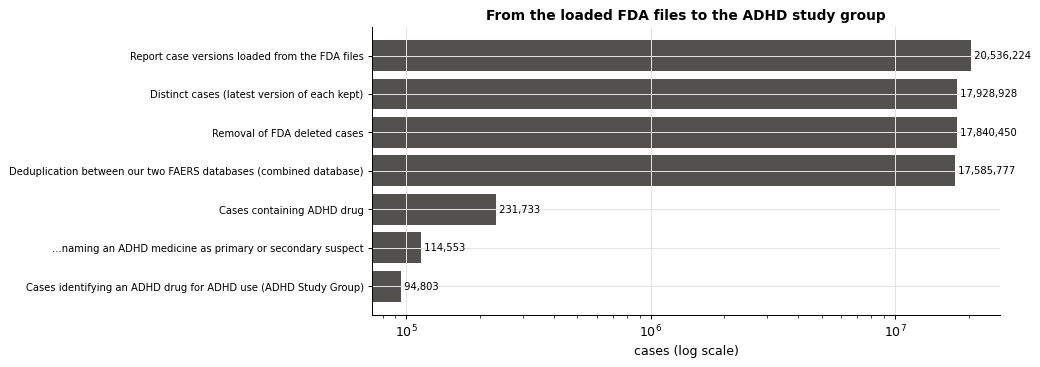

,cases,dropped,% of previous step
Report case versions loaded from the FDA files,20536224,0,NaN
Distinct cases (latest version of each kept),17928928,2607296,87.3
Removal of FDA deleted cases,17840450,88478,99.5
Deduplication between our two FAERS databases (combined database),17585777,254673,98.6
Cases containing ADHD drug,231733,17354044,1.3
...naming an ADHD medicine as primary or secondary suspect,114553,117180,49.4
Cases identifying an ADHD drug for ADHD use (ADHD Study Group),94803,19750,82.8


In [ ]:
# @title Drill down
steps = ingestion_drawdown(con)
show_drawdown(steps, "From the loaded FDA files to the ADHD study group")

**What this shows**: Of the 17.6 million cleaned cases (inaccordance to FDA revision control & removal of duplicate records/overlap), only 1.3% (231,733) name an ADHD medication. Roughly half of the cases name them as only  a background drug, not as a possible cause for an adverse affect. As such, the cases were excluded. Of the 114,553 that remain, 83% pass for ADHD identified use. This gives our study group a total of 94,803 cases.

**Which medicines the study group is made of?**

In [ ]:
# @title Study Group Medication Representation
cases = study_cases(con)
drugs = study_rows(
    con,
    "kept_drug_indication",
    "role_cod, adhd_medication, cohort_medication_matched, adhd_class, mapping_method, "
    "indication_status, moieties",
)
exposure = drugs[
    drugs["adhd_medication"].fillna(False)
    & drugs["role_cod"].isin(["PS", "SS"])
    & drugs["cohort_medication_matched"].fillna(False)
].explode("moieties")
exposure = exposure.rename(columns={"moieties": "ingredient"}).merge(
    cases[["caseid", "rq1_group", "init_date"]], on="caseid"
)
exposure["year"] = exposure["init_date"].dt.year

by_moiety = (
    exposure.groupby(["adhd_class", "ingredient"])["caseid"].nunique().sort_values().rename("cases")
)

by_moiety.sort_values(ascending=False).to_frame()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (4 outputs left out)

/tmp/ipykernel_1124/821580988.py:163: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cases[filled] = cases[filled].fillna(False).astype(bool)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

cases
adhd_class   ingredient                  
STIMULANT    methylphenidate        35722
             amphetamine            26399
             dextroamphetamine      22021
             lisdexamfetamine       19130
NONSTIMULANT atomoxetine             8862
STIMULANT    dexmethylphenidate      2919
ALPHA2       guanfacine              2562
NONSTIMULANT viloxazine              1154
STIMULANT    serdexmethylphenidate    650
ALPHA2       clonidine                342
STIMULANT    methamphetamine          196

**This shows:** Methylphenidate (35,722 cases) and the amphetamines (amphetamine, dextroamphetamine and lisdexamfetamine) make up most of the study group. Atomoxetine (8,862) is most of the nonstimulant group. Guanfacine (2,562), viloxazine (1,154) and clonidine (342) are smaller. Methamphetamine (196 cases) is the prescription medicine Desoxyn, not the illegal Meth.

**Reports per year by medication.** This shows the mix changes over time.

In [ ]:
# @title Study group linked by year and drug
yearly = exposure.groupby(["year", "moiety"])["caseid"].nunique().unstack(fill_value=0)
yearly = yearly.loc[2013:2025, yearly.sum().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 4.5))
image = ax.imshow(yearly.T, aspect="auto", cmap="Blues")
ax.set_yticks(range(yearly.shape[1]), yearly.columns)
ax.set_xticks(range(yearly.shape[0]), yearly.index, rotation=90)
ax.grid(False)
fig.colorbar(image, label="cases")
ax.set_title("Study-group cases by initial case year and suspect medication")
plt.show()

### A5. Outputs used by the other notebooks
* `rq1_group` on every study case: **STIMULANT**, **NONSTIMULANT** (alpha-2 agonists
  included, flagged `alpha2`) or **MULTI_ADHD_CLASS** (reported, never compared).
* `rq1_group_confirmed`: the same rule using only drug rows whose own indication is
  ADHD (a sensitivity check in RQ1 and RQ2).
* Group sizes:

In [ ]:
# @title Summary of drug groups
cases["rq1_group"].value_counts().to_frame("cases")

,cases
rq1_group,
STIMULANT,81998
NONSTIMULANT,11805
MULTI_ADHD_CLASS,1000


## Keyword and term searches that define the qualified events

### 1. Question
FAERS records each reaction as a MedDRA "preferred term" such as `tachycardia` or `drug ineffective`. Our research questions talk about other topics: cardiovascular, psychiatric and dependence events; ineffectiveness, withdrawal, misuse, abuse and addiction. Due to this we needed to develop a list of which terms could be inscope for each topic.

### 2. Methodology
The official MedDRA groupings require a licence which we do not have, so we built our own list in three steps:
1. **Identify our groups** from the research questions and the wording of the FDA's 2023 label change, which names misuse, abuse and addiction separately.
2. **Fill each group with terms**, marking clear terms **narrow** and less specific ones **broad** (the broad list is inclusive of the narrow one).
3. **Check against the real data**: every term must appear in our reports, and keyword searches plus a read of the most common terms in ADHD reports look for anything missed. Terms we considered and rejected are kept in an `excluded` list with the reason.


A report counts toward a group when it lists any term within the group, by exact lower-case match. No stemming or fuzzy matching, so the rule is fully reproducible.

### 3. Methods: Term List

In [ ]:
# @title Terms list
terms = pd.read_csv(io.StringIO(TERMS_CSV))
print(f"{len(terms)} terms, list version {terms['list_version'].unique()[0]}")
terms.pivot_table(index="group", columns="tier", values="pt", aggfunc="size", fill_value=0)

417 terms, list version v0.1


tier,broad,excluded,narrow
group,,,
abuse,0,0,4
addiction,3,0,2
cardiovascular,53,0,103
dependence,4,0,3
excluded,0,29,0
ineffectiveness,12,0,10
misuse,4,0,5
overdose,6,0,3
product_quality_supply,7,0,23


### 4. EDA of the event groups
**Coverage:** How many of the study group's most reported terms fall in a group?

In [ ]:
# @title Event Group Summary
top = reported.sort_values("cases", ascending=False).head(30).copy()
top["group"] = top["pt"].map(where).fillna("-")
top.reset_index(drop=True)

,pt,cases,group
0,drug ineffective,17537,ineffectiveness (narrow)
1,off label use,6763,excluded (excluded)
2,no adverse event,6702,excluded (excluded)
3,product substitution issue,6097,product_quality_supply (narrow)
4,product quality issue,5880,product_quality_supply (narrow)
5,headache,5459,-
6,disturbance in attention,4736,-
7,anxiety,4709,psychiatric (narrow)
8,fatigue,4422,-
9,feeling abnormal,3720,-


This shows the 30 most reported terms, 16 fall in a group. Twelve are general
side effects or usage notes that no research question asks about, such as headache, fatigue and nausea. The other two, "off label use" and "no adverse event", were left out on purpose because they do not describe an event.

**How common each group is, by its drug classification?** (Precentage of cases with at least one term; narrow list solid, broad list light).

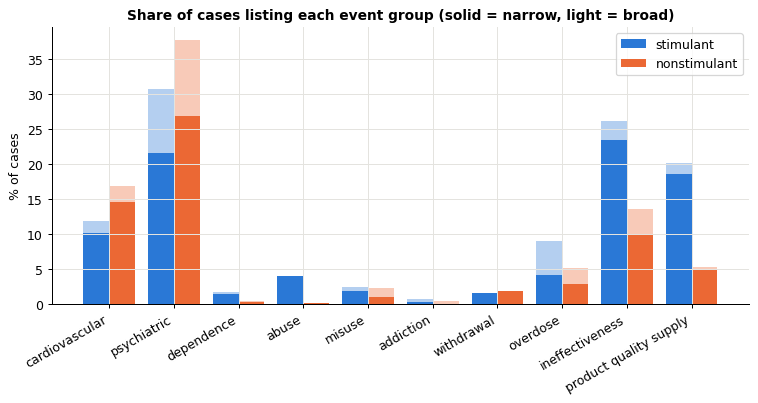

rq1_group,NONSTIMULANT,STIMULANT
cardiovascular__narrow,14.6,10.1
cardiovascular__broad,16.9,11.8
psychiatric__narrow,26.9,21.7
psychiatric__broad,37.8,30.7
dependence__narrow,0.3,1.5
dependence__broad,0.4,1.7
abuse__narrow,0.2,4.0
abuse__broad,0.2,4.0
misuse__narrow,1.1,1.8
misuse__broad,2.4,2.5


In [ ]:
# @title Commonality by Drug Classification
groups = [
    "cardiovascular",
    "psychiatric",
    "dependence",
    "abuse",
    "misuse",
    "addiction",
    "withdrawal",
    "overdose",
    "ineffectiveness",
    "product_quality_supply",
]
two = cases[cases["rq1_group"] != "MULTI_ADHD_CLASS"]
prevalence = (
    100 * two.groupby("rq1_group")[[f"{g}_{t}" for g in groups for t in ("narrow", "broad")]].mean()
)
prevalence.columns = [
    c.replace("_narrow", "__narrow").replace("_broad", "__broad") for c in prevalence.columns
]
fig, ax = plt.subplots(figsize=(10, 4))
x = range(len(groups))
for i, cls in enumerate(["STIMULANT", "NONSTIMULANT"]):
    pos = [v + (i - 0.5) * 0.4 for v in x]
    ax.bar(
        pos,
        prevalence.loc[cls, [f"{g}__broad" for g in groups]],
        0.4,
        color=COLORS[cls],
        alpha=0.35,
    )
    ax.bar(
        pos,
        prevalence.loc[cls, [f"{g}__narrow" for g in groups]],
        0.4,
        color=COLORS[cls],
        label=cls.lower(),
    )
ax.set_xticks(list(x), [g.replace("_", " ") for g in groups], rotation=30, ha="right")
ax.set_ylabel("% of cases")
ax.set_title("Share of cases listing each event group (solid = narrow, light = broad)")
ax.legend()
plt.show()
prevalence.T.round(1)

This shows ineffectiveness (23.4% vs 9.8%) and product quality or supply problems (18.7% vs 4.9%) are much more common instimulant reports, and abuse terms appear almost only there (4.0% vs 0.2%). Cardiovascular (10.1% vs 14.6%) and psychiatric (21.7% vs 26.9%) terms are more common in non-stimulant reports. Withdrawal is about the same in both (1.5% vs 1.8%). The broad lists
raise every share a little but keep the same order.

**Overlap between adverse event groups:** Abuse, misuse, overdose and dependence often appear on the same report, which is why each group gets its own yes/no flag instead of one combined category. Each cell is the % of cases with the row group that also list the column group (narrow lists, stimulant and nonstimulant cases together):

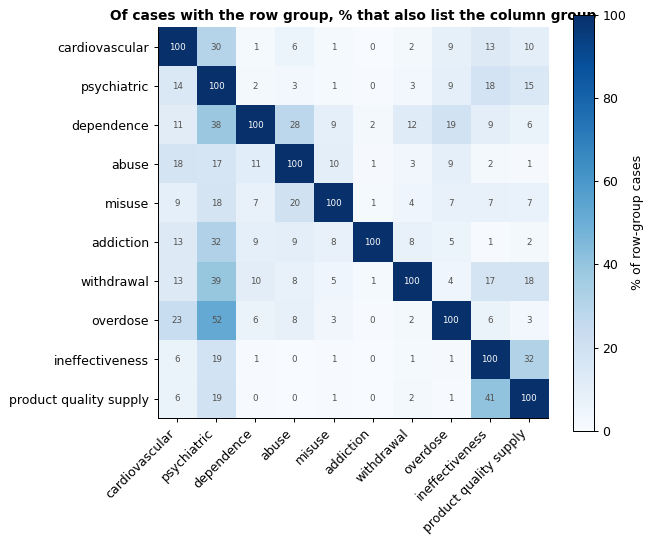

In [ ]:
# @title Event Overlap
narrow = two[[f"{g}_narrow" for g in groups]].set_axis(groups, axis=1)
overlap = pd.DataFrame(
    {b: [100 * narrow.loc[narrow[a], b].mean() for a in groups] for b in groups}, index=groups
)
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(overlap, cmap="Blues", vmin=0, vmax=100)
labels = [re.sub("_", " ", g) for g in groups]
ax.set_xticks(range(len(groups)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(groups)), labels)
ax.grid(False)
for i in range(len(groups)):
    for j in range(len(groups)):
        ax.text(
            j,
            i,
            f"{overlap.iat[i, j]:.0f}",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if overlap.iat[i, j] > 60 else GREY,
        )
fig.colorbar(image, label="% of row-group cases")
ax.set_title("Of cases with the row group, % that also list the column group")
plt.show()